# 05 · Evaluation in depth
Threshold-free comparison, the HDFS end-of-log effect, and the streaming replay.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import PARSED_DIR, RAW_DIR, RESULTS_DIR, SEQUENCES_DIR

BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.edgecolor": "#888",
                     "axes.titleweight": "bold", "axes.titlesize": 11})
pd.set_option("display.max_colwidth", 120)

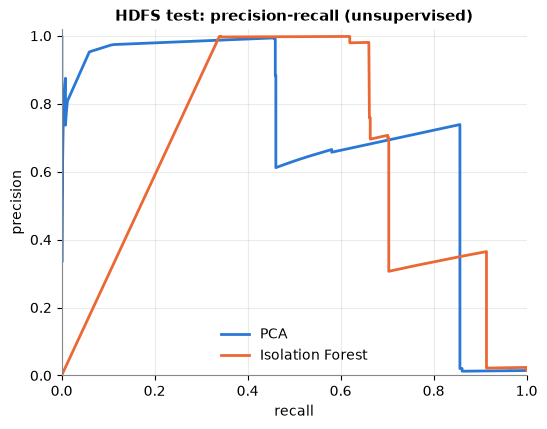

In [2]:
import joblib
from sklearn.metrics import precision_recall_curve
from src.config import ARTIFACTS_DIR
from src.grouping.split import chronological_split
s = pd.read_parquet(SEQUENCES_DIR / "hdfs_sessions.parquet")
train, val, test = chronological_split(s)
art = joblib.load(ARTIFACTS_DIR / "hdfs" / "classical.joblib")
Xt = art["vectorizer"].transform(test.events)
fig, ax = plt.subplots(figsize=(6, 4.5))
colors = {"PCA": BLUE, "Isolation Forest": ORANGE}
for name, color in colors.items():
    p, r, _ = precision_recall_curve(test.label, art["models"][name]["model"].score(Xt))
    ax.plot(r, p, color=color, lw=2, label=name)
ax.set(xlabel="recall", ylabel="precision", title="HDFS test: precision-recall (unsupervised)", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(frameon=False); plt.show()

## Why HDFS test scores drop
The test sessions start in the last ~2.5 hours of the log, so many never reach their final stage before the file ends.

In [3]:
tpl = pd.read_csv(PARSED_DIR / "hdfs_templates.csv").set_index("event_id").template
delete_ids = {e for e, t in tpl.items() if "Deleting block" in t}
pd.DataFrame({name: {"normal sessions reaching 'Deleting block'": f"{part[part.label == 0].events.map(lambda e: bool(delete_ids & set(e))).mean():.1%}",
                     "median length (normal)": part[part.label == 0].n_events.median(),
                     "median length (anomalous)": part[part.label == 1].n_events.median()}
              for name, part in (("train", train), ("val", val), ("test", test))})

,train,val,test
normal sessions reaching 'Deleting block',93.3%,89.5%,39.9%
median length (normal),19.0,19.0,13.0
median length (anomalous),20.0,20.0,4.0


Truncated normal sessions look unusual to any model that learned complete sessions, which raises false alarms, and the very short anomalous test sessions give sequence models little order to learn from. A production system would score sessions as they progress, which is what the streaming replay does.

## Streaming replay

In [4]:
from src.streaming.replay import summarize
for ds in ("hdfs", "bgl"):
    path = RESULTS_DIR / "stream" / f"{ds}_scores.csv"
    if path.exists():
        print(ds.upper()); summarize(pd.read_csv(path), ds); print()

HDFS

180,538 groups, 4,512 anomalous, 4,641 alerts
precision 0.968  recall 0.996  F1 0.982  (TP 4492, FP 149, FN 20)
detection delay (minutes): median 30.8, p90 113.3, max 132.2

BGL

897 groups, 160 anomalous, 94 alerts
precision 0.957  recall 0.562  F1 0.709  (TP 90, FP 4, FN 70)
detection delay (minutes): median 55.7, p90 189.8, max 410.9

